# Urban Heat Explorer: the dashboard

Member 4, step 3 (slides 23–24). `urbanheat serve` starts the app; open http://127.0.0.1:8000. Built for anyone,
not only experts, and it shows **only data that exist**: the 422 satellite image pairs of 281 places.

**How a user works with it (the five steps in the side panel):**
1. **Choose a place**: type its name (place names from GeoNames) or click an orange dot. If a place has several
   images, choose the date. A card shows the typical ground temperature, the hottest and coolest 5 %, how built-up
   and green it is, and how accurate the model is there.
2. **What to show**: satellite photo, hot and cool spots, surface temperature, greenery, buildings, water (more
   layers for experts: model output, error, reasons per factor, Grad-CAM).
3. **Why is this spot hot?**: click a point in the image (or "Hottest spot" / "Coolest spot"); the circle (300 m,
   600 m or 1 km) gets a plain sentence ("the ground here is 47 °C, 2.1 °C hotter than the city's typical 45 °C")
   and the reasons as bars in °C.
4. **What if this area changed?**: three plain presets (turn built-up land into a park, add street trees, build on
   green land) re-estimate the circle with Member 3's engine.
5. **Ask a question**: the assistant from `02_genai_rag`, with suggested questions.

"About the model" explains the model in plain words (accuracy, what it relies on, main findings from `01_xai`).

| Endpoint | Returns |
|---|---|
| `GET /api/places` | places with their images, layer list, what-if presets |
| `GET /api/summary/{image}` | place card numbers, hottest and coolest spot |
| `GET /api/layer/{image}/{layer}` | transparent PNG + EPSG:4326 bounds + legend with words at both ends |
| `POST /api/spot` | facts and reasons (°C) for a circle around a clicked point |
| `POST /api/whatif` | change map and statistics for a preset inside that circle |
| `POST /api/ask` | the assistant, with the facts of the place or spot |
| `GET /api/insights` | "About the model" panel |
| `GET /api/export/{image}/pred.tif`, `attr.tif` | GeoTIFF downloads |

Below, the same API is called from Python and the returned maps are drawn.

In [1]:
import warnings, base64, io, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from fastapi.testclient import TestClient
from urbanheat.app import assistant
from urbanheat.app.server import create_app, PRESETS
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 90
app = create_app()                     # dataset from the config, model runs/m3_lite16_kd
ws, api = app.state.ws, TestClient(app)
PID = "EMIT_243"
summary = api.get(f"/api/summary/{PID}").json()
HOT = summary["spots"]["hottest"]      # the dashboard's "Hottest spot" button
print(ws.run, "|", len(ws.info), "images |", summary["name"], summary["region"], summary["date"], "| hottest spot", HOT)

m3_lite16_kd | 422 images | Barranquilla Atlantico 2025-03-11 | hottest spot {'lat': 10.961177759124956, 'lng': -74.84110646212541, 'diff_c': 3.7863082885742188}


## Place names (made once, offline)

In [2]:
# src/urbanheat/app/places.csv was made with reverse_geocoder (offline GeoNames cities1000, CC BY 4.0):
#   rg.search([(lat, lon) for each dataset cell], mode=1) -> name, admin1 (region), cc (country)
places = api.get("/api/places").json()["places"]
print(len(places), "places;", sum(len(p["images"]) > 1 for p in places), "with several images")
pd.DataFrame([dict(place=p["name"], region=p["region"], country=p["cc"], climate=p["climate"], images=len(p["images"]))
              for p in places]).sample(8, random_state=0)

281 places; 92 with several images


,place,region,country,climate,images
89,Aurangabad,Maharashtra,IN,tropical,2
12,Dohar,Dhaka,BD,tropical,1
124,Kumta,Karnataka,IN,tropical,1
221,Kibungo,Eastern Province,RW,tropical,2
64,Driyorejo,East Java,ID,tropical,1
219,Butare,Southern Province,RW,tropical,2
201,Ungogo,Kano,NG,tropical,1
200,Ogaminan,Kogi,NG,tropical,2


## Step 1–2: the place card and the basic layers

,Barranquilla
pid,EMIT_243
name,Barranquilla
region,Atlantico
cc,CO
date,2025-03-11
sensor,EMIT
climate,tropical
typical_c,45.2
hottest_c,48.1
coolest_c,40.0


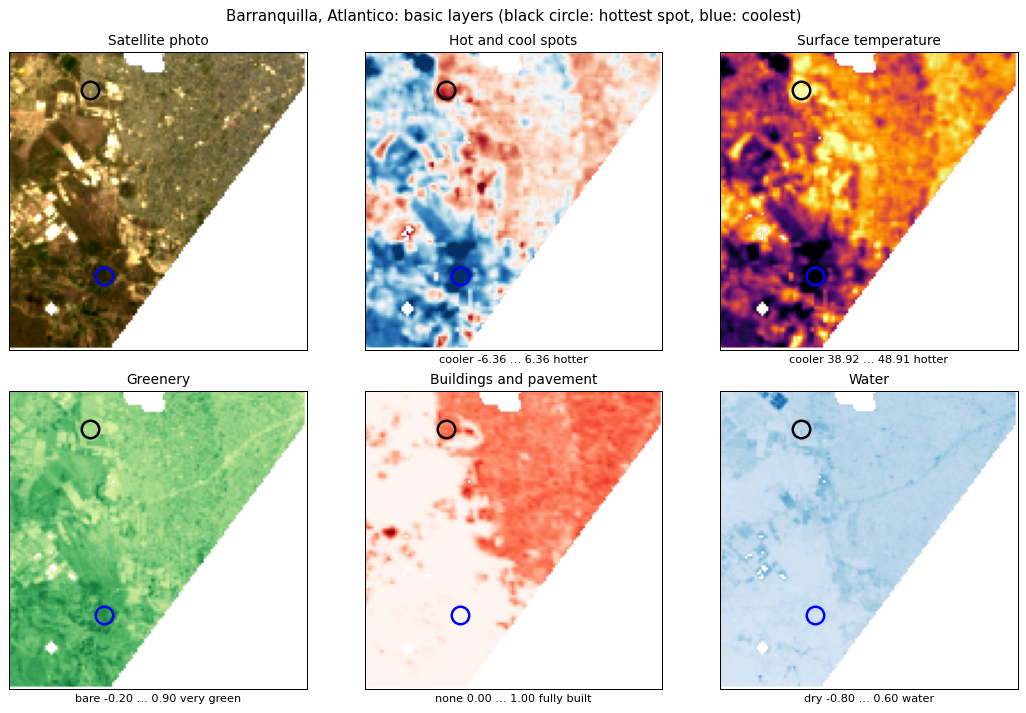

In [3]:
display(pd.Series({k: v for k, v in summary.items() if k != "spots"}).to_frame(summary["name"]))

def img(layer):
    return np.asarray(Image.open(io.BytesIO(base64.b64decode(layer["url"].split(",", 1)[1]))))

names = ["rgb", "hotspots", "lst", "NDVI", "built_share", "MNDWI"]
fig, axs = plt.subplots(2, 3, figsize=(12, 8))
for ax, nm in zip(axs.flat, names):
    L = api.get(f"/api/layer/{PID}/{nm}").json()
    (s0, w0), (n0, e0) = L["bounds"]
    ax.imshow(img(L), extent=[w0, e0, s0, n0]); ax.set_title(L["label"], fontsize=11)
    if L["vmin"] is not None: ax.set_xlabel(f"{L['low']} {L['vmin']:.2f} … {L['vmax']:.2f} {L['high']}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    for k, c in (("hottest", "k"), ("coolest", "b")):
        ax.plot(summary["spots"][k]["lng"], summary["spots"][k]["lat"], "o", mfc="none", mec=c, ms=14, mew=2)
plt.suptitle(f"{summary['name']}, {summary['region']}: basic layers (black circle: hottest spot, blue: coolest)")
plt.tight_layout(); plt.show()

## Step 3: why is the hottest spot hot?

The ground here is 46.5 °C, 1.27 vs. the city's typical 45.2 °C (model: 0.52).


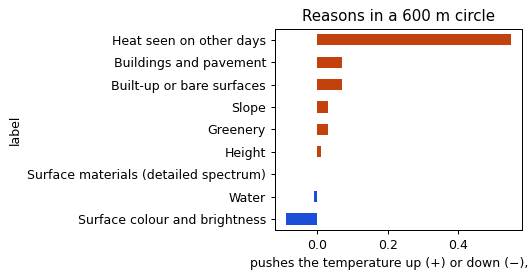

Attributions describe what the model learned from data (associations), not physical causes.


In [4]:
ex = api.post("/api/spot", json={"pid": PID, "lat": HOT["lat"], "lng": HOT["lng"], "radius_m": 600}).json()
f = ex["facts"]
print(f"The ground here is {f['measured_surface_c']} °C, {f['measured_vs_typical_c']} vs. the city's typical "
      f"{f['city_typical_surface_c']} °C (model: {f['model_vs_typical_c']}).")
r = pd.DataFrame(ex["reasons"]).set_index("label")["effect_c"].sort_values()
r.plot.barh(figsize=(6, 3.2), color=["#c2410c" if v > 0 else "#1d4ed8" for v in r])
plt.xlabel("pushes the temperature up (+) or down (−), °C"); plt.title("Reasons in a 600 m circle"); plt.tight_layout(); plt.show()
print(ex["note"])

## Step 4: what if this area changed?

,changes,mean_c,most_cooling_c,most_warming_c,pixels,mean_outside_c
what_if,,,,,,
Turn built-up land into a park,"{""NDVI"": 0.34, ""NDBI"": -0.2, ""built_share"": -0.3}",-0.347,-1.246,0.079,321,0.009
Add street trees and grass,"{""NDVI"": 0.1, ""NDBI"": -0.06}",-0.156,-0.450,0.034,321,0.003
Build on green land,"{""NDVI"": -0.34, ""NDBI"": 0.2, ""built_share"": 0.3}",0.161,-0.150,0.702,321,-0.008


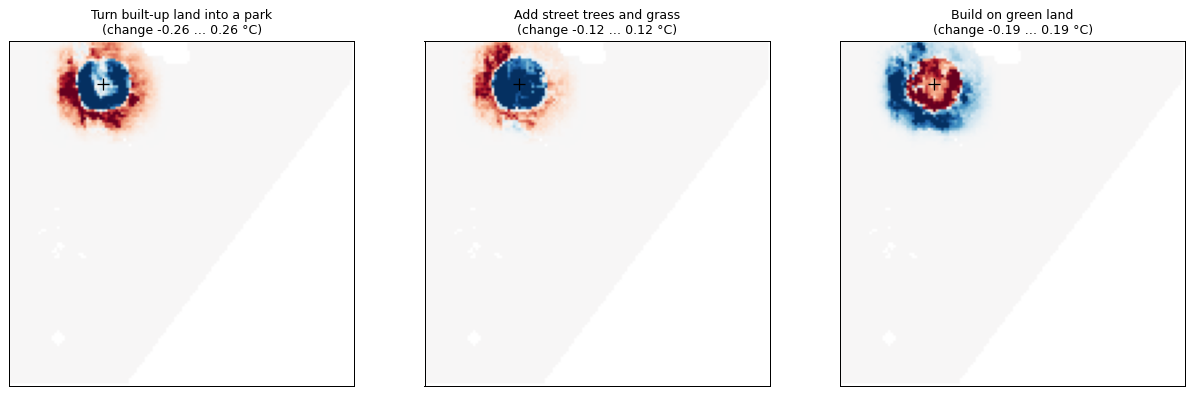

Modelled estimate of land surface temperature change; not a causal guarantee.


In [5]:
rows, maps = [], {}
for key, (label, changes) in PRESETS.items():
    w = api.post("/api/whatif", json={"pid": PID, "lat": HOT["lat"], "lng": HOT["lng"], "radius_m": 600, "preset": key}).json()
    rows.append(dict(what_if=label, changes=json.dumps(changes), **{k: round(v, 3) for k, v in w["stats"].items()}))
    maps[label] = w["layer"]
display(pd.DataFrame(rows).set_index("what_if"))
fig, axs = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (label, L) in zip(axs, maps.items()):
    (s0, w0), (n0, e0) = L["bounds"]
    ax.imshow(img(L), extent=[w0, e0, s0, n0]); ax.plot(HOT["lng"], HOT["lat"], "k+", ms=10)
    ax.set_title(f"{label}\n(change {L['vmin']:.2f} … {L['vmax']:.2f} °C)", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
print(w["note"])

## "About the model" panel

- Heat seen on other days explains 68 % of the model's prediction: places that were hot on other days are predicted hot again.
- Changing only built_share +0.1 in a 2 km block: +0.006 °C on average (cooler in 64 % of test cities).
- Changing only NDVI +0.1 in a 2 km block: -0.017 °C on average (cooler in 70 % of test cities).
- Changing only NDBI +0.1 in a 2 km block: +0.071 °C on average (cooler in 14 % of test cities).


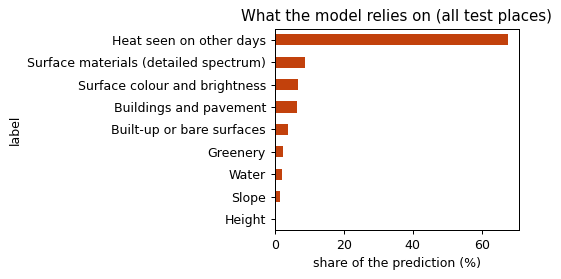

,r2,mae,n
group,,,
all,0.784,0.981,748055
arid,0.685,1.251,92885
cold,0.394,2.937,8432
temperate,0.916,0.734,66996
tropical,0.796,0.938,579742
EMIT,0.827,0.910,424783
ENMAP,0.837,0.783,88029
HYPERION,0.704,1.185,235243


In [6]:
ins = api.get("/api/insights").json()
print("\n".join("- " + f for f in ins["findings"]))
imp = pd.DataFrame(ins["importance"]["all"]).set_index("label").sort_values("share_pct")
imp["share_pct"].plot.barh(figsize=(6, 3.2), color="#c2410c")
plt.xlabel("share of the prediction (%)"); plt.title("What the model relies on (all test places)"); plt.tight_layout(); plt.show()
display(pd.DataFrame(ins["accuracy"]).set_index("group").round(3))

## Map export (CONTRACTS section 5)

In [7]:
out = Path("../../runs/m3_lite16_kd/maps"); out.mkdir(parents=True, exist_ok=True)
p = out / f"{PID}_pred.tif"                      # the dashboard's "Download maps" link
p.write_bytes(api.get(f"/api/export/{PID}/pred.tif").content)
import rasterio
with rasterio.open(p) as r:
    print(p.name, r.crs, r.shape, r.descriptions, "| no uncertainty band: every model was trained once (one seed)")

EMIT_243_pred.tif EPSG:4326 (130, 130) ('predicted_lst_c',) | no uncertainty band: every model was trained once (one seed)


## Notes

- The page loads Leaflet 1.9.4 from unpkg and the OpenStreetMap tiles, so the browser needs internet access. The
  API itself runs offline.
- Everything carries the caveats: ground (not air) temperature, model estimates rather than causes, and what-if
  responses about half the size seen in past satellite data.
- The what-if maps show a ring of the **opposite sign just outside the circle**: the model reads surface factors
  relative to their surroundings (`01_xai`). The dashboard reports the mean inside the circle.
- Startup reads the dataset (about 15 s). The reasons of an image are computed on first use (about 3 s on CPU)
  and then cached.